# Void pathology and its resolution

A pure Galileon sourced by an underdensity can drive the discriminant of the gradient equation negative, leaving no real $y'$ — an imaginary fifth force. Adding a Chameleon potential gives the field a density-tracking minimum to sit on, and the discriminant stays non-negative over a much wider range of Vainshtein strength.

This notebook reproduces both panels:

- **top** — $\min_x \Delta/(\epsilon\tilde\alpha x)^2$ over the plane of density contrast $\delta = \hat\rho_{\rm in}-1$ and Vainshtein strength $\beta$, with the two critical boundaries
- **bottom** — the radial discriminant for three configurations at $\delta = -0.7$

The sweep in the top panel is 56×56 solves and takes a while; it is cached to `void_depth.npz`, so re-running the notebook reuses it.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter
from matplotlib.lines import Line2D

import styling
import mixed_screening as ms
import void_depth_sweep as sweep

styling.apply()

## Parameters

The conformal coupling is the canonical $f(R)$ value $\alpha = 1/\sqrt6$, for which the kinetic renormalisation is exactly $\tilde\alpha = 2$.

In [2]:
A, at, BG = sweep.A, sweep.at, sweep.BG
RIN = 0.30                      # delta = -0.70, the slice shown in the lower panel
XI = sweep.XI                   # mesh, clustered on the screening shell
xg = np.linspace(0.0, 3.0, 800) # reaches x = 0; the discriminant has a finite plateau there

print(f'A = eps*at = {A},  rho_bg = {BG},  rho_in = {RIN}')

A = eps*at = 0.2,  rho_bg = 1.0,  rho_in = 0.3


## The sweep

Loads `void_depth.npz` if present, otherwise runs the 56×56 grid (slow).

In [3]:
if os.path.exists(sweep.OUT):
    d = np.load(sweep.OUT)
    print('loaded cached sweep')
else:
    print('computing sweep (56x56 solves, several minutes)...')
    sweep.run()
    d = np.load(sweep.OUT)

ri, be, Dmin = d['rho_ins'], d['betas'], d['Dmin']
yb = be / A**2          # beta normalised by (eps*at)^2
dlt = ri - 1.0          # density contrast
SC = A**2               # converts normalised beta back to bare beta
Dm = np.clip(np.nan_to_num(Dmin, nan=-2.0), -1, 1)
YTOP = 6.0              # trim the dead zone above beta_hat ~ 0.54

# mixed-screening boundary: where min_x Delta crosses zero, per density column
bC = np.full(len(ri), np.nan)
for j in range(len(ri)):
    col = Dm[:, j]
    if col[0] > 0 > col[-1]:
        bC[j] = np.interp(0.0, col[::-1], yb[::-1])

ybV = 3.0 / (8 * (BG - RIN)) / at**2        # shift-symmetric pure Vainshtein
ybC = np.interp(RIN, ri, np.nan_to_num(bC, nan=ybV * 2))
print(f'at delta = {RIN-1:.2f}:  beta_crit_V = {ybV:.4f},  beta_crit_V+Ch = {ybC:.4f}'
      f'   (factor {ybC/ybV:.1f})')

loaded cached sweep
at delta = -0.70:  beta_crit_V = 0.1339,  beta_crit_V+Ch = 1.3295   (factor 9.9)


## The three marked configurations

One below both thresholds, one between them (where the Chameleon rescues an otherwise pathological configuration), and one above both.

The discriminant is evaluated through the perfect square $\Delta = (\epsilon\tilde\alpha x + 4\beta y')^2$, which is better behaved near the origin than dividing a vanishing charge by $x^3$.

In [4]:
# Colour marks which configuration; line style marks which theory. The three
# colours are escut's shared categorical triplet, with the two cool members
# swapped: the rescued case sits on the map's dark band, where the lighter of
# the two reads better.
CFG = [('resolved',     0.60 * ybV,          styling.CASES[1]),
       ('rescued',      np.sqrt(ybV * ybC),  styling.CASES[0]),
       ('pathological', 1.55 * ybC,          styling.CASES[2])]

def mixed_D(ybv):
    """Radial discriminant of the solved mixed system."""
    beta = ybv * A**2
    s = ms.solve(A=A, beta=beta, rho_in=RIN, rho_bg=BG, eps_edge=0.05,
                 x_init=XI, tol=1e-4, max_nodes=5_000_000)
    yp = np.gradient(s.sol(xg)[0], xg)
    return ms.discriminant_ratio_from_gradient(xg, yp, A, beta)

def pure_D(ybv):
    """Pure Galileon: analytic, sourced by the mass perturbation alone."""
    xs = np.maximum(xg, 1e-6)
    IV = (RIN - 1.0) * np.minimum(xs, 1.0)**3 / 3.0
    return 1.0 / at**2 + 8 * ybv * IV / xs**3

curves = {nm: (pure_D(y), None if nm == 'pathological' else mixed_D(y))
          for nm, y, _ in CFG}
for nm, (p, m) in curves.items():
    print(f'{nm:<14} min pure = {np.nanmin(p):+.3f}'
          + (f'   min mixed = {np.nanmin(m):+.3f}' if m is not None else '   (no real solution)'))


resolved       min pure = +0.100   min mixed = +0.931
rescued        min pure = -0.538   min mixed = +0.644
pathological   min pure = -3.597   (no real solution)


## Figure

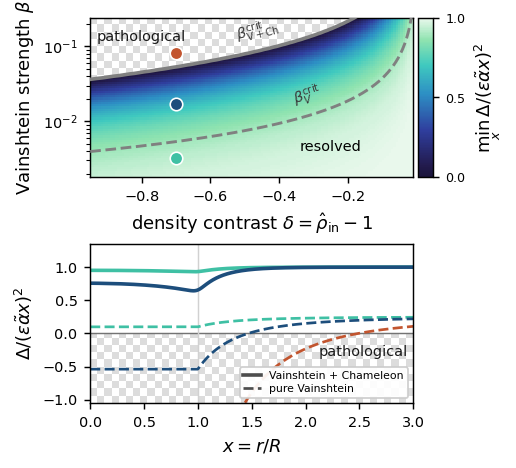

In [5]:
# Delta < 0 means no real branch exists, so that region is marked the way an
# image marks absent pixels - a checkerboard - rather than tinted as though it
# held a value. The checker is plot-specific; the palette comes from escut.
from matplotlib.patches import Rectangle
from matplotlib.path import Path

CHK_A, CHK_B, CHK_MM = '#ffffff', '#dcdcdc', 1.4      # square size in mm at print size

def checker(axis, clip, zorder=2):
    """Transparency-style checkerboard, squares measured in display space so
    they stay square whatever the axes aspect, clipped to `clip`."""
    axis.figure.canvas.draw()
    bb = axis.get_window_extent().transformed(axis.figure.dpi_scale_trans.inverted())
    sq = CHK_MM / 25.4
    nx = max(2, int(round(bb.width / sq))); ny = max(2, int(round(bb.height / sq)))
    pat = (np.add.outer(np.arange(ny), np.arange(nx)) % 2).astype(float)
    im = axis.imshow(pat, cmap=ListedColormap([CHK_A, CHK_B]), extent=[0, 1, 0, 1],
                     transform=axis.transAxes, origin='lower', interpolation='nearest',
                     aspect='auto', zorder=zorder)
    im.set_clip_path(clip)
    return im

pos = styling.sequential()(np.linspace(0.12, 1.0, 256))
neg = np.tile(np.array(mcolors.to_rgba(CHK_A)), (256, 1))
cmap = ListedColormap(np.vstack([neg, pos]), 'void')

# One neutral for both boundaries. Labels are set separately: both land on light
# ground, so they take a dark grey the line itself cannot use (beta_crit_V+Ch
# sits at Delta = 0, the colourmap's darkest point, where a dark line vanishes).
C_LINE, C_TXT, FS = '#808080', '#3a3a3a', 10

fig = plt.figure(figsize=(styling.COL, styling.COL * 1.132))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 0.045], height_ratios=[1, 1],
                      hspace=0.42, wspace=0.03)
ax, cax, axl = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 0])

# ---- top: the plane ----
im = ax.pcolormesh(dlt, yb * SC, Dm, cmap=cmap, norm=Normalize(-1, 1), shading='nearest')
cs = ax.contourf(dlt, yb * SC, Dm, levels=[float(Dm.min()) - 1e-3, 0.0], colors='none')
paths = cs.get_paths()
if paths:
    checker(ax, (Path.make_compound_path(*paths), ax.transData), zorder=2)
ax.set_yscale('log'); ax.set_xlim(dlt[0], dlt[-1]); ax.set_ylim(0.045 * SC, YTOP * SC)
ax.yaxis.set_major_locator(LogLocator(base=10.0))
ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10.0))
ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=12))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r'density contrast $\delta=\hat\rho_{\rm in}-1$', fontsize=FS)
ax.set_ylabel(r'Vainshtein strength $\beta$', fontsize=FS)
ax.tick_params(labelsize=FS - 2)
fig.canvas.draw()

def annotate_line(xs, ys, x0, txt, color, ls='-', lw=1.8, D=10, fsz=None, tcolor=None):
    """Draw a boundary and set its label just beside it, rotated to match."""
    ax.plot(xs, ys, color=color, ls=ls, lw=lw, zorder=5)
    i = int(np.argmin(np.abs(xs - x0))); j0, j1 = max(i - 4, 0), min(i + 4, len(xs) - 1)
    p1 = ax.transData.transform((xs[j0], ys[j0])); p2 = ax.transData.transform((xs[j1], ys[j1]))
    rot = np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0])); rr = np.radians(rot)
    ax.annotate(txt, (xs[i], ys[i]), textcoords='offset points',
                xytext=(D * np.sin(rr), -D * np.cos(rr)), color=tcolor or color,
                fontsize=fsz or FS - 2, rotation=rot, rotation_mode='anchor',
                ha='center', va='center', zorder=6)

rig = np.linspace(ri[0], ri[-1], 300)
bV = 3.0 / (8 * (BG - rig)) / at**2
annotate_line(rig - 1.0, bV * SC, -0.30, r'$\beta^{\rm crit}_V$',
              C_LINE, ls='--', lw=1.6, D=-11, tcolor=C_TXT)

mC = np.isfinite(bC); xs_bC, ys_bC = dlt[mC], bC[mC]
if np.nanmax(ys_bC) < YTOP and np.any(ys_bC > 0):          # extend to the trimmed top edge
    xs_bC = np.append(xs_bC, np.interp(YTOP, ys_bC, xs_bC)); ys_bC = np.append(ys_bC, YTOP)
annotate_line(xs_bC, ys_bC * SC, -0.45, r'$\beta^{\rm crit}_{\rm V+Ch}$',
              C_LINE, ls='-', lw=2.0, D=-11, tcolor=C_TXT)

ax.text(-0.80, 3.0 * SC, 'pathological', color='0.1', fontsize=FS - 2, ha='center')
ax.text(-0.25, 0.10 * SC, 'resolved', color='k', fontsize=FS - 2, ha='center')
for nm, y, c in CFG:
    if y < YTOP:
        ax.scatter([-0.70], [y * SC], s=48, marker='o', facecolor=c,
                   edgecolor='w', lw=0.9, zorder=6)

cb = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, 1), cmap=ListedColormap(pos)), cax=cax)
cb.set_label(r'$\min_x\,\Delta/(\epsilon\tilde\alpha x)^2$', fontsize=FS)
cb.ax.tick_params(labelsize=FS - 3); cb.set_ticks([0, 0.5, 1.0])

# ---- bottom: radial discriminant ----
axl.axhspan(-10, 0, color=CHK_A, zorder=0)
checker(axl, Rectangle((0, -10), 3, 10, transform=axl.transData), zorder=0.5)
axl.axhline(0, color='0.45', lw=0.8, zorder=1.5)          # Delta = 0 reference
axl.text(2.95, -0.28, 'pathological', color='0.1', fontsize=FS - 2, ha='right', va='center')
axl.axvline(1, color='0.82', lw=0.8)
for nm, y, c in CFG:
    p, m = curves[nm]
    axl.plot(xg, p, color=c, lw=1.5, ls='--')
    if m is not None:
        axl.plot(xg, m, color=c, lw=2.0, ls='-')
axl.set_xlim(0, 3); axl.set_ylim(-1.05, 1.35)
axl.set_xlabel(r'$x=r/R$', fontsize=FS)
axl.set_ylabel(r'$\Delta/(\epsilon\tilde\alpha x)^2$', fontsize=FS)
axl.tick_params(labelsize=FS - 2)
axl.legend(handles=[Line2D([], [], color='0.3', lw=2.0, ls='-', label='Vainshtein + Chameleon'),
                    Line2D([], [], color='0.3', lw=1.5, ls='--', label='pure Vainshtein')],
           loc='lower right', fontsize=FS - 4, framealpha=0.92,
           handlelength=1.6, labelspacing=0.25, borderpad=0.35)

fig.savefig('void_stack.png', bbox_inches='tight', dpi=220)
plt.show()
